In [1]:
from pathlib import Path
import random
import subprocess as sbp
import pandas as pd
import numpy as np
import scipy.optimize as opt
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import seaborn as sns
from tqdm.auto import tqdm

SAMPLES = 1000000

random.seed(231)

popes = pd.read_csv("popes-list.csv")

In [ ]:
def run_test(n, k, configuration, samples=1e8):
    seed = random.randint(0, 2**16)

    cmd = f"ewens-sampler sample --seed {seed} -n {n} -k {k} {int(samples)} | ewens-sampler test watterson '{configuration}'"

    result = sbp.getoutput(cmd).split()
    count, total = int(result[0]), int(result[1])

    return count / total


def fit_theta(n, k):
    def ll(theta):
        return -k * np.log(theta) + np.sum([np.log(theta + i) for i in range(n)])

    result = opt.minimize_scalar(ll, bounds=(0, 1e7), method="bounded")

    return result.x

rows = []

for i in tqdm(list(range(44, popes.shape[0] + 1))):
    d = popes.iloc[:i, :]

    year = d["start"].iloc[-1]
    pope = d["pope"].iloc[-1]

    n, k = d.shape[0], len(d["name"].unique())

    configuration = " ".join([str(x) for x in d["name"].value_counts()])

    p_tail = run_test(n, k, configuration, samples=SAMPLES)
    theta = fit_theta(n, k)

    rows.append(
        {
            "year": year,
            "pope": pope,
            "n": n,
            "k": k,
            "p_tail": p_tail,
            "theta": theta,
        }
    )

ps = pd.DataFrame.from_records(rows)



Text(-0.1, 1.1, 'B')

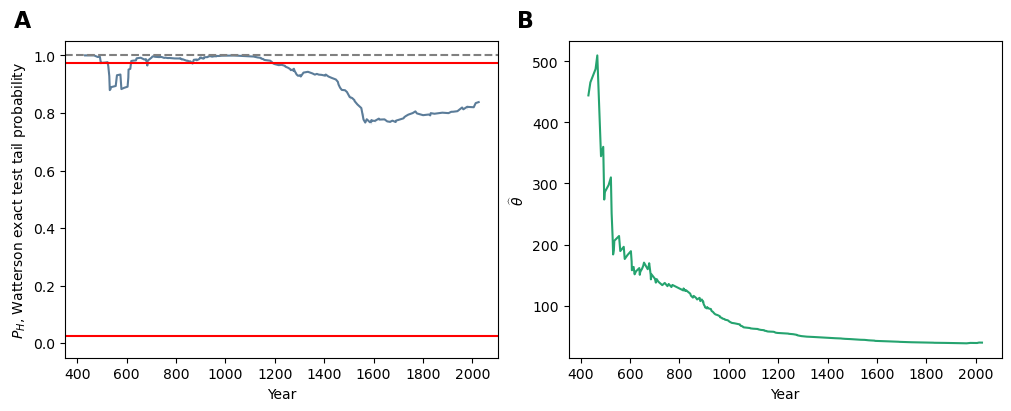

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True, sharex=True)
colors = sns.xkcd_palette(["slate blue", "teal green"])

sns.lineplot(ps, x="year", y="p_tail", ax=axs[0], color=colors[0])

axs[0].set_xlabel("Year")
axs[0].set_ylabel("$P_H$, Watterson exact test tail probability")

axs[0].axhline(1, color="gray", linestyle="--")
axs[0].axhline(0.025, color="red")
axs[0].axhline(0.975, color="red")
axs[0].set_ylim(-0.05, 1.05)

sns.lineplot(ps, x="year", y="theta", ax=axs[1], color=colors[1])

axs[1].set_xlabel("Year")
axs[1].set_ylabel("$\\widehat \\theta$")

axs[0].text(
    -0.1,
    1.1,
    "A",
    transform=axs[0].transAxes,
    fontsize=16,
    fontweight="bold",
    va="top",
    ha="center",
)

axs[1].text(
    -0.1,
    1.1,
    "B",
    transform=axs[1].transAxes,
    fontsize=16,
    fontweight="bold",
    va="top",
    ha="center",
)

In [ ]:
def run_test_conditional(n, k, configuration, initial_configuration, samples=1e8):
    seed = random.randint(0, 2**16)
    cmd = f"ewens-sampler sample --seed {seed} -n {n} -k {k} --initial-configuration '{initial_configuration}' {int(samples)} | ewens-sampler test watterson '{configuration}'"

    result = sbp.getoutput(cmd).split()
    count, total = int(result[0]), int(result[1])

    return count / total


def fit_theta_conditional(n, k, n0, k0):
    if k == k0:
        # return 0 as no mutations => theta = 4Nmu = 0
        return 0
    else:

        def ll(theta):
            return -(k - k0) * np.log(theta) + np.sum(
                [np.log(theta + i) for i in range(n0, n)]
            )

        result = opt.minimize_scalar(ll, bounds=(0, 1e7), method="bounded")

        return result.x


def get_windows(size):
    x = np.arange(432, 2025 - size + 1)
    return zip(x, x + size)


# size of the temporal window
size = 200

rows = []

for s, e in tqdm(list(get_windows(size))):
    d = popes.query("start <= @s")

    year = d["start"].iloc[-1]
    pope = d["pope"].iloc[-1]
    initial_configuration = " ".join([str(x) for x in d["name"].value_counts()])
    n0 = d.shape[0]
    k0 = len(d["name"].unique())

    d_end = popes.query("start < @e")
    end_configuration = " ".join([str(x) for x in d_end["name"].value_counts()])
    n = d_end.shape[0]
    k = len(d_end["name"].unique())

    p_tail = run_test_conditional(
        n, k, end_configuration, initial_configuration, SAMPLES
    )

    theta = fit_theta_conditional(n, k, n0, k0)

    d_win = popes.query("start >= @s and start < @e")
    k_win = len(d_win["name"].unique())
    n_win = d_win.shape[0]

    win_counts = d_win["name"].value_counts()
    win_freqs = (win_counts / win_counts.sum()).values
    win_entropy = -(win_freqs * np.log(win_freqs)).sum()

    rows.append(
        {
            "year": year,
            "pope": pope,
            "n": n,
            "k": k,
            "window_start": s,
            "window_end": e,
            "window_size": size,
            "n0": n0,
            "k0": k0,
            "n_win": n_win,
            "k_win": k_win,
            "win_entropy": win_entropy,
            "theta": theta,
            "p_tail": p_tail,
        }
    )

ps_windowed = pd.DataFrame.from_records(rows)



Text(-0.1, 1.1, 'C')

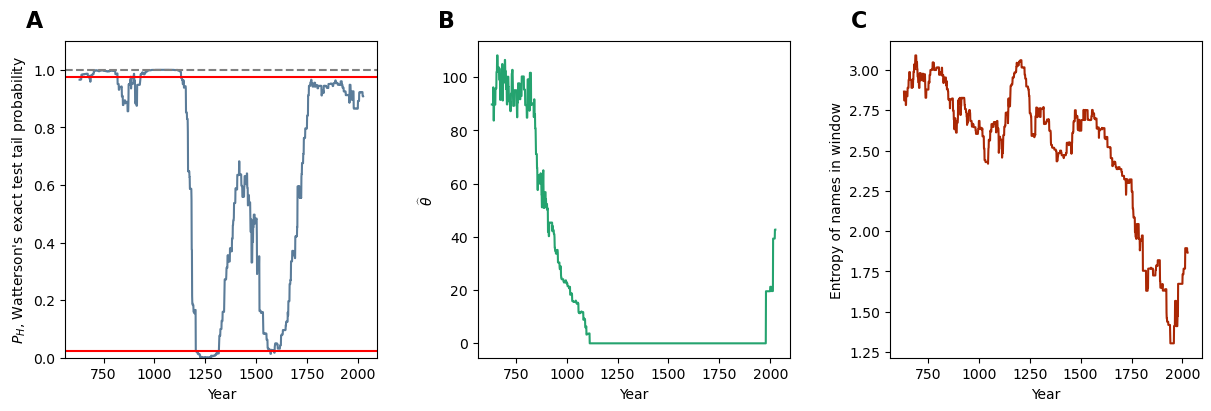

In [6]:
fig, axs = plt.subplots(
    1,
    3,
    figsize=(12, 4),
    constrained_layout=True,
    sharex=True,
    gridspec_kw={"wspace": 0.1},
)
colors = sns.xkcd_palette(["slate blue", "teal green", "rust red"])

dplot = ps_windowed.query(f"window_size == @size")

sns.lineplot(dplot, x="window_end", y="p_tail", ax=axs[0], color=colors[0])

axs[0].set_xlabel("Year")
axs[0].set_ylabel("$P_H$, Watterson's exact test tail probability")

axs[0].axhline(1, color="gray", linestyle="--")
axs[0].axhline(0.025, color="red")
axs[0].axhline(0.975, color="red")
axs[0].set_ylim(0, 1.1)

sns.lineplot(dplot, x="window_end", y="theta", ax=axs[1], color=colors[1])

axs[1].set_xlabel("Year")
axs[1].set_ylabel("$\\widehat \\theta$")


sns.lineplot(dplot, x="window_end", y="win_entropy", ax=axs[2], color=colors[2])
axs[2].set_xlabel("Year")
axs[2].set_ylabel("Entropy of names in window")

axs[0].text(
    -0.1,
    1.1,
    "A",
    transform=axs[0].transAxes,
    fontsize=16,
    fontweight="bold",
    va="top",
    ha="center",
)

axs[1].text(
    -0.1,
    1.1,
    "B",
    transform=axs[1].transAxes,
    fontsize=16,
    fontweight="bold",
    va="top",
    ha="center",
)

axs[2].text(
    -0.1,
    1.1,
    "C",
    transform=axs[2].transAxes,
    fontsize=16,
    fontweight="bold",
    va="top",
    ha="center",
)


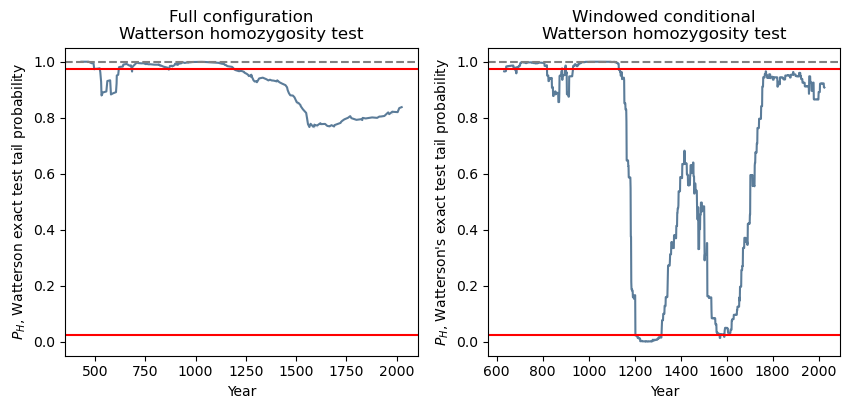

In [12]:
fig, axs = plt.subplots(1,2, figsize=(10,4))

sns.lineplot(ps, x="year", y="p_tail", ax=axs[0], color=colors[0])

axs[0].set_xlabel("Year")
axs[0].set_ylabel("$P_H$, Watterson exact test tail probability")

axs[0].axhline(1, color="gray", linestyle="--")
axs[0].axhline(0.025, color="red")
axs[0].axhline(0.975, color="red")
axs[0].set_ylim(-0.05, 1.05)
axs[0].set_title("Full configuration\nWatterson homozygosity test")

sns.lineplot(dplot, x="window_end", y="p_tail", ax=axs[1], color=colors[0])

axs[1].set_xlabel("Year")
axs[1].set_ylabel("$P_H$, Watterson's exact test tail probability")

axs[1].axhline(1, color="gray", linestyle="--")
axs[1].axhline(0.025, color="red")
axs[1].axhline(0.975, color="red")
axs[1].set_ylim(-0.05, 1.05)
axs[1].set_title("Windowed conditional\nWatterson homozygosity test") 

fig.savefig("watterson.pdf", bbox_inches="tight")
fig.savefig("watterson.png", dpi=600, bbox_inches="tight")

In [19]:
x = "chr22 20 2020\n"
x.split()

['chr22', '20', '2020']